# AI-Based Pharmaceutical Inventory Recommendation System

This notebook generates inventory recommendations by combining
current inventory levels, historical demand, and machine learning
demand forecasts.

Objectives:
- Identify medicines requiring replenishment
- Estimate stock coverage
- Calculate recommended reorder quantities
- Prioritize inventory actions
- Generate actionable business recommendations

In [7]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

In [8]:
print("Inventory columns:")
print(inventory.columns.tolist())

print("\nProducts columns:")
print(products.columns.tolist())

print("\nSales columns:")
print(sales.columns.tolist())

Inventory columns:
['inventory_id', 'product_id', 'city', 'stock_in', 'stock_out', 'current_stock', 'inventory_status']

Products columns:
['product_id', 'medicine_name', 'category', 'manufacturer', 'cost_price', 'selling_price', 'expiry_days']

Sales columns:
['order_id', 'order_date', 'customer_id', 'product_id', 'supplier_id', 'city', 'channel', 'quantity', 'unit_price', 'discount_pct', 'revenue', 'profit', 'returned', 'return_reason', 'payment_method']


In [9]:
sales["order_date"] = pd.to_datetime(
    sales["order_date"]
)

In [10]:
monthly_demand = (
    sales.groupby(
        [
            "product_id",
            pd.Grouper(
                key="order_date",
                freq="MS"
            )
        ]
    )["quantity"]
    .sum()
    .reset_index()
)

monthly_demand.head()

,product_id,order_date,quantity
0,MED000001,2020-01-01,2100
1,MED000001,2020-02-01,2204
2,MED000001,2020-03-01,2442
3,MED000001,2020-04-01,1493
4,MED000001,2020-05-01,1663


In [5]:
sales["order_date"] = pd.to_datetime(
    sales["order_date"]
)

monthly_sales = (
    sales
    .groupby(
        [
            "product_id",
            pd.Grouper(
                key="order_date",
                freq="MS"
            )
        ]
    )["quantity"]
    .sum()
    .reset_index()
    .rename(
        columns={"quantity": "monthly_demand"}
    )
)

print("Monthly sales shape:", monthly_sales.shape)
print(monthly_sales.head(10))

Monthly sales shape: (61979, 3)
  product_id order_date  monthly_demand
0  MED000001 2020-01-01            2100
1  MED000001 2020-02-01            2204
2  MED000001 2020-03-01            2442
3  MED000001 2020-04-01            1493
4  MED000001 2020-05-01            1663
5  MED000001 2020-06-01            1993
6  MED000001 2020-07-01            3082
7  MED000001 2020-08-01            4314
8  MED000001 2020-09-01            4475
9  MED000001 2020-10-01            2404


In [11]:
latest_date = monthly_demand["order_date"].max()

recent_demand = monthly_demand[
    monthly_demand["order_date"] >=
    latest_date - pd.DateOffset(months=2)
]

In [12]:
avg_recent_demand = (
    recent_demand
    .groupby("product_id")["quantity"]
    .mean()
    .reset_index()
)

avg_recent_demand.rename(
    columns={
        "quantity": "avg_monthly_demand"
    },
    inplace=True
)

avg_recent_demand.head()

,product_id,avg_monthly_demand
0,MED000001,1965.333333
1,MED000002,2553.666667
2,MED000003,2098.666667
3,MED000004,2153.000000
4,MED000005,2249.666667


In [13]:
inventory_data = inventory[
    [
        "product_id",
        "city",
        "stock_in",
        "stock_out",
        "current_stock",
        "inventory_status"
    ]
].copy()

In [14]:
recommendation_df = inventory_data.merge(
    avg_recent_demand,
    on="product_id",
    how="left"
)

In [15]:
recommendation_df.head()

,product_id,city,stock_in,stock_out,current_stock,inventory_status,avg_monthly_demand
0,MED001847,Ahmedabad,4148,1288,2860,Healthy,22.0
1,MED002398,Ahmedabad,8890,7182,1708,Healthy,NaN
2,MED001996,Mumbai,5631,5692,0,Stockout,16.0
3,MED000413,Ahmedabad,3563,3121,442,Healthy,9.0
4,MED001895,Mumbai,6301,4556,1745,Healthy,63.0


In [16]:
product_info = products[
    [
        "product_id",
        "medicine_name",
        "category",
        "manufacturer",
        "cost_price",
        "selling_price"
    ]
].copy()

In [17]:
recommendation_df = recommendation_df.merge(
    product_info,
    on="product_id",
    how="left"
)

In [18]:
recommendation_df["avg_monthly_demand"] = (
    recommendation_df["avg_monthly_demand"]
    .fillna(0)
)

In [19]:
recommendation_df["stock_coverage_months"] = np.where(
    recommendation_df["avg_monthly_demand"] > 0,
    recommendation_df["current_stock"] /
    recommendation_df["avg_monthly_demand"],
    np.inf
)

In [20]:
recommendation_df["expected_3_month_demand"] = (
    recommendation_df["avg_monthly_demand"] * 3
)

In [21]:
recommendation_df["reorder_quantity"] = np.maximum(
    recommendation_df["expected_3_month_demand"] -
    recommendation_df["current_stock"],
    0
)

In [22]:
recommendation_df["reorder_quantity"] = (
    np.ceil(
        recommendation_df["reorder_quantity"]
    ).astype(int)
)

In [23]:
def generate_recommendation(row):

    stock = row["current_stock"]
    demand = row["avg_monthly_demand"]
    coverage = row["stock_coverage_months"]

    if demand == 0 and stock > 0:
        return "No Recent Demand - Review Stock"

    if stock == 0 and demand > 0:
        return "URGENT - Stockout"

    if coverage < 1:
        return "URGENT - Reorder"

    if coverage < 2:
        return "HIGH PRIORITY - Reorder Soon"

    if coverage > 6:
        return "OVERSTOCK - Avoid Purchase"

    return "STOCK SUFFICIENT"

In [24]:
recommendation_df["recommendation"] = (
    recommendation_df.apply(
        generate_recommendation,
        axis=1
    )
)

In [25]:
def assign_priority(recommendation):

    if "URGENT" in recommendation:
        return "High"

    if "HIGH PRIORITY" in recommendation:
        return "Medium"

    if "OVERSTOCK" in recommendation:
        return "Low"

    return "Normal"

In [26]:
recommendation_df["priority"] = (
    recommendation_df["recommendation"]
    .apply(assign_priority)
)

In [27]:
recommendation_df["estimated_reorder_cost"] = (
    recommendation_df["reorder_quantity"] *
    recommendation_df["cost_price"]
)

In [28]:
final_recommendations = recommendation_df[
    [
        "product_id",
        "medicine_name",
        "category",
        "manufacturer",
        "city",
        "current_stock",
        "avg_monthly_demand",
        "stock_coverage_months",
        "expected_3_month_demand",
        "reorder_quantity",
        "estimated_reorder_cost",
        "inventory_status",
        "recommendation",
        "priority"
    ]
].copy()

In [29]:
final_recommendations.head(20)

,product_id,medicine_name,category,manufacturer,city,current_stock,avg_monthly_demand,stock_coverage_months,expected_3_month_demand,reorder_quantity,estimated_reorder_cost,inventory_status,recommendation,priority
0,MED001847,Paracetamol 608,Analgesics,Abbott,Ahmedabad,2860,22.0,130.000000,66.0,0,0.00,Healthy,OVERSTOCK - Avoid Purchase,Low
1,MED002398,Crocin 790,Antibiotics,Torrent,Ahmedabad,1708,0.0,inf,0.0,0,0.00,Healthy,No Recent Demand - Review Stock,Normal
2,MED001996,Pantoprazole 279,Analgesics,Dr Reddy's,Mumbai,0,16.0,0.000000,48.0,48,62944.32,Stockout,URGENT - Stockout,High
3,MED000413,Azithromycin 446,Neurology,Lupin,Ahmedabad,442,9.0,49.111111,27.0,0,0.00,Healthy,OVERSTOCK - Avoid Purchase,Low
4,MED001895,Cetirizine 385,Antibiotics,Dr Reddy's,Mumbai,1745,63.0,27.698413,189.0,0,0.00,Healthy,OVERSTOCK - Avoid Purchase,Low
5,MED000505,Metformin 553,Antibiotics,Glenmark,Mumbai,0,9.0,0.000000,27.0,27,43188.39,Stockout,URGENT - Stockout,High
6,MED001626,Cetirizine 836,Analgesics,Lupin,Pune,1542,45.0,34.266667,135.0,0,0.00,Healthy,OVERSTOCK - Avoid Purchase,Low
7,MED000441,Paracetamol 444,Neurology,Zydus,Ahmedabad,0,15.0,0.000000,45.0,45,35423.55,Stockout,URGENT - Stockout,High
8,MED000334,Atorvastatin 669,Cardiology,Cipla,Pune,2919,30.0,97.300000,90.0,0,0.00,Healthy,OVERSTOCK - Avoid Purchase,Low
9,MED001635,Montelukast 846,Antibiotics,Sun Pharma,Ahmedabad,1010,24.0,42.083333,72.0,0,0.00,Healthy,OVERSTOCK - Avoid Purchase,Low


In [30]:
priority_order = {
    "High": 1,
    "Medium": 2,
    "Low": 3,
    "Normal": 4
}

final_recommendations["priority_order"] = (
    final_recommendations["priority"]
    .map(priority_order)
)

final_recommendations = (
    final_recommendations
    .sort_values(
        ["priority_order", "reorder_quantity"],
        ascending=[True, False]
    )
    .drop(columns="priority_order")
    .reset_index(drop=True)
)

In [31]:
urgent_medicines = final_recommendations[
    final_recommendations["priority"] == "High"
]

print(
    "Urgent medicines:",
    len(urgent_medicines)
)

urgent_medicines.head(20)

Urgent medicines: 8775


,product_id,medicine_name,category,manufacturer,city,current_stock,avg_monthly_demand,stock_coverage_months,expected_3_month_demand,reorder_quantity,estimated_reorder_cost,inventory_status,recommendation,priority
0,MED000019,Metformin 715,Antibiotics,Mankind,Pune,0,2567.333333,0.000000,7702.0,7702,1536857.08,Stockout,URGENT - Stockout,High
1,MED000019,Metformin 715,Antibiotics,Mankind,Pune,0,2567.333333,0.000000,7702.0,7702,1536857.08,Stockout,URGENT - Stockout,High
2,MED000019,Metformin 715,Antibiotics,Mankind,Delhi,0,2567.333333,0.000000,7702.0,7702,1536857.08,Stockout,URGENT - Stockout,High
3,MED000002,Dolo 650,Respiratory,Abbott,Ahmedabad,0,2553.666667,0.000000,7661.0,7661,2514186.98,Stockout,URGENT - Stockout,High
4,MED000002,Dolo 650,Respiratory,Abbott,Delhi,0,2553.666667,0.000000,7661.0,7661,2514186.98,Stockout,URGENT - Stockout,High
5,MED000002,Dolo 650,Respiratory,Abbott,Mumbai,0,2553.666667,0.000000,7661.0,7661,2514186.98,Stockout,URGENT - Stockout,High
6,MED000002,Dolo 650,Respiratory,Abbott,Hyderabad,0,2553.666667,0.000000,7661.0,7661,2514186.98,Stockout,URGENT - Stockout,High
7,MED000019,Metformin 715,Antibiotics,Mankind,Hyderabad,71,2567.333333,0.027655,7702.0,7631,1522689.74,Low Stock,URGENT - Reorder,High
8,MED000002,Dolo 650,Respiratory,Abbott,Ahmedabad,117,2553.666667,0.045816,7661.0,7544,2475789.92,Low Stock,URGENT - Reorder,High
9,MED000012,Augmentin,Analgesics,Alkem,Delhi,0,2513.666667,0.000000,7541.0,7541,24282170.82,Stockout,URGENT - Stockout,High


In [32]:
recommendation_summary = (
    final_recommendations[
        "recommendation"
    ]
    .value_counts()
    .reset_index()
)

recommendation_summary.columns = [
    "Recommendation",
    "Medicine Count"
]

recommendation_summary

,Recommendation,Medicine Count
0,OVERSTOCK - Avoid Purchase,20213
1,No Recent Demand - Review Stock,9074
2,URGENT - Stockout,8114
3,STOCK SUFFICIENT,1479
4,URGENT - Reorder,661
5,HIGH PRIORITY - Reorder Soon,459


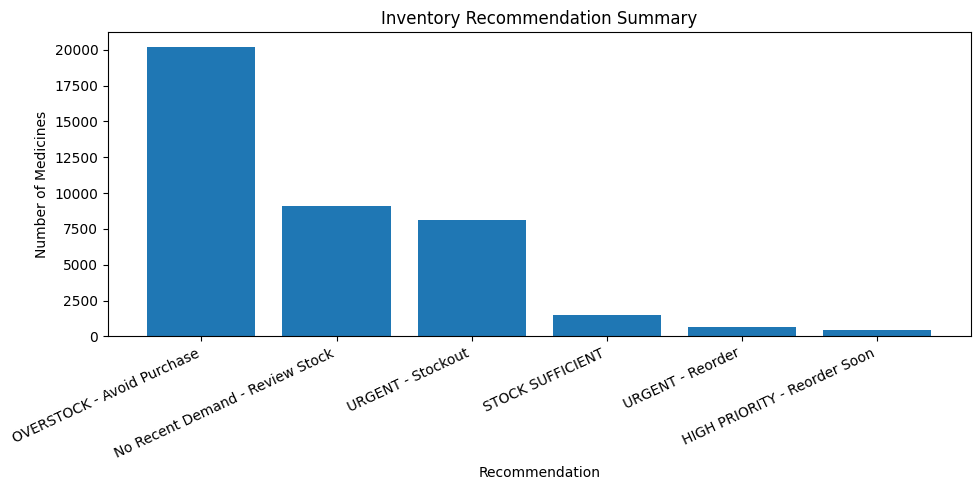

In [33]:
plt.figure(figsize=(10, 5))

plt.bar(
    recommendation_summary["Recommendation"],
    recommendation_summary["Medicine Count"]
)

plt.title("Inventory Recommendation Summary")
plt.xlabel("Recommendation")
plt.ylabel("Number of Medicines")

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()
plt.show()

In [34]:
top_reorder = (
    final_recommendations[
        final_recommendations["reorder_quantity"] > 0
    ]
    .sort_values(
        "reorder_quantity",
        ascending=False
    )
    .head(10)
)

top_reorder[
    [
        "medicine_name",
        "category",
        "current_stock",
        "avg_monthly_demand",
        "reorder_quantity",
        "recommendation"
    ]
]

,medicine_name,category,current_stock,avg_monthly_demand,reorder_quantity,recommendation
0,Metformin 715,Antibiotics,0,2567.333333,7702,URGENT - Stockout
1,Metformin 715,Antibiotics,0,2567.333333,7702,URGENT - Stockout
2,Metformin 715,Antibiotics,0,2567.333333,7702,URGENT - Stockout
5,Dolo 650,Respiratory,0,2553.666667,7661,URGENT - Stockout
3,Dolo 650,Respiratory,0,2553.666667,7661,URGENT - Stockout
6,Dolo 650,Respiratory,0,2553.666667,7661,URGENT - Stockout
4,Dolo 650,Respiratory,0,2553.666667,7661,URGENT - Stockout
7,Metformin 715,Antibiotics,71,2567.333333,7631,URGENT - Reorder
8,Dolo 650,Respiratory,117,2553.666667,7544,URGENT - Reorder
10,Augmentin,Analgesics,0,2513.666667,7541,URGENT - Stockout


In [35]:
output_dir = "../Data/ML Outputs"

os.makedirs(
    output_dir,
    exist_ok=True
)

In [36]:
final_recommendations.to_csv(
    f"{output_dir}/inventory_recommendations.csv",
    index=False
)

In [37]:
recommendation_summary.to_csv(
    f"{output_dir}/recommendation_summary.csv",
    index=False
)

In [38]:
print("Files saved successfully:")

print(
    os.listdir(output_dir)
)

Files saved successfully:
['inventory_recommendations.csv', 'recommendation_summary.csv']


In [39]:
forecast_2026 = pd.read_csv(
    "../Data/ML Outputs/medicine_demand_forecast_2026.csv"
)

forecast_2026.head()

,product_id,forecast_month,forecast_demand,medicine_name,category
0,MED000001,2026-01-01,2169,Paracetamol,Antibiotics
1,MED000001,2026-02-01,2160,Paracetamol,Antibiotics
2,MED000001,2026-03-01,2364,Paracetamol,Antibiotics
3,MED000001,2026-04-01,1543,Paracetamol,Antibiotics
4,MED000001,2026-05-01,1590,Paracetamol,Antibiotics


In [40]:
print("Forecast shape:", forecast_2026.shape)
print("Columns:", forecast_2026.columns.tolist())

Forecast shape: (30000, 5)
Columns: ['product_id', 'forecast_month', 'forecast_demand', 'medicine_name', 'category']


In [41]:
annual_forecast = (
    forecast_2026
    .groupby(
        [
            "product_id",
            "medicine_name",
            "category"
        ]
    )["forecast_demand"]
    .sum()
    .reset_index()
)

annual_forecast.rename(
    columns={
        "forecast_demand": "forecast_2026_demand"
    },
    inplace=True
)

annual_forecast.head()

,product_id,medicine_name,category,forecast_2026_demand
0,MED000001,Paracetamol,Antibiotics,30557
1,MED000002,Dolo 650,Respiratory,31608
2,MED000003,Crocin,Analgesics,31155
3,MED000004,Metformin,Gastro,31029
4,MED000005,Azithromycin,Analgesics,31111


In [42]:
annual_forecast["avg_forecast_monthly_demand"] = (
    annual_forecast["forecast_2026_demand"] / 12
)

In [43]:
forecast_inventory = inventory[
    [
        "product_id",
        "city",
        "current_stock",
        "inventory_status"
    ]
].copy()

In [44]:
integrated_df = forecast_inventory.merge(
    annual_forecast,
    on="product_id",
    how="left"
)

In [45]:
integrated_df.head()

,product_id,city,current_stock,inventory_status,medicine_name,category,forecast_2026_demand,avg_forecast_monthly_demand
0,MED001847,Ahmedabad,2860,Healthy,Paracetamol 608,Analgesics,488,40.666667
1,MED002398,Ahmedabad,1708,Healthy,Crocin 790,Antibiotics,489,40.750000
2,MED001996,Mumbai,0,Stockout,Pantoprazole 279,Analgesics,489,40.750000
3,MED000413,Ahmedabad,442,Healthy,Azithromycin 446,Neurology,490,40.833333
4,MED001895,Mumbai,1745,Healthy,Cetirizine 385,Antibiotics,488,40.666667


In [46]:
integrated_df[
    "forecast_2026_demand"
] = integrated_df[
    "forecast_2026_demand"
].fillna(0)

integrated_df[
    "avg_forecast_monthly_demand"
] = integrated_df[
    "avg_forecast_monthly_demand"
].fillna(0)

In [47]:
integrated_df["forecast_stock_coverage_months"] = np.where(
    integrated_df["avg_forecast_monthly_demand"] > 0,
    integrated_df["current_stock"] /
    integrated_df["avg_forecast_monthly_demand"],
    np.inf
)

In [48]:
integrated_df["required_3_month_stock"] = (
    integrated_df["avg_forecast_monthly_demand"] * 3
)

In [49]:
integrated_df["forecast_reorder_quantity"] = np.maximum(
    integrated_df["required_3_month_stock"] -
    integrated_df["current_stock"],
    0
)

In [50]:
integrated_df["forecast_reorder_quantity"] = (
    np.ceil(
        integrated_df["forecast_reorder_quantity"]
    ).astype(int)
)

In [51]:
def generate_forecast_recommendation(row):

    stock = row["current_stock"]
    demand = row["avg_forecast_monthly_demand"]
    coverage = row["forecast_stock_coverage_months"]

    if demand == 0 and stock > 0:
        return "NO FORECASTED DEMAND - REVIEW STOCK"

    if stock == 0 and demand > 0:
        return "URGENT - STOCKOUT RISK"

    if coverage < 1:
        return "URGENT - REORDER"

    if coverage < 2:
        return "HIGH PRIORITY - REORDER SOON"

    if coverage > 6:
        return "OVERSTOCK - AVOID PURCHASE"

    return "STOCK SUFFICIENT"

In [52]:
integrated_df["forecast_recommendation"] = (
    integrated_df.apply(
        generate_forecast_recommendation,
        axis=1
    )
)

In [53]:
def forecast_priority(recommendation):

    if "URGENT" in recommendation:
        return "High"

    if "HIGH PRIORITY" in recommendation:
        return "Medium"

    if "OVERSTOCK" in recommendation:
        return "Low"

    return "Normal"

In [54]:
integrated_df["forecast_priority"] = (
    integrated_df[
        "forecast_recommendation"
    ].apply(forecast_priority)
)

In [55]:
integrated_df = integrated_df.merge(
    products[
        [
            "product_id",
            "cost_price",
            "selling_price"
        ]
    ],
    on="product_id",
    how="left"
)

In [56]:
integrated_df["forecast_reorder_cost"] = (
    integrated_df["forecast_reorder_quantity"] *
    integrated_df["cost_price"]
)

In [57]:
final_ai_recommendations = integrated_df[
    [
        "product_id",
        "medicine_name",
        "category",
        "city",
        "current_stock",
        "forecast_2026_demand",
        "avg_forecast_monthly_demand",
        "forecast_stock_coverage_months",
        "required_3_month_stock",
        "forecast_reorder_quantity",
        "cost_price",
        "forecast_reorder_cost",
        "inventory_status",
        "forecast_recommendation",
        "forecast_priority"
    ]
].copy()

In [58]:
final_ai_recommendations.head(20)

,product_id,medicine_name,category,city,current_stock,forecast_2026_demand,avg_forecast_monthly_demand,forecast_stock_coverage_months,required_3_month_stock,forecast_reorder_quantity,cost_price,forecast_reorder_cost,inventory_status,forecast_recommendation,forecast_priority
0,MED001847,Paracetamol 608,Analgesics,Ahmedabad,2860,488,40.666667,70.327869,122.00,0,1193.60,0.00,Healthy,OVERSTOCK - AVOID PURCHASE,Low
1,MED002398,Crocin 790,Antibiotics,Ahmedabad,1708,489,40.750000,41.914110,122.25,0,3463.75,0.00,Healthy,OVERSTOCK - AVOID PURCHASE,Low
2,MED001996,Pantoprazole 279,Analgesics,Mumbai,0,489,40.750000,0.000000,122.25,123,1311.34,161294.82,Stockout,URGENT - STOCKOUT RISK,High
3,MED000413,Azithromycin 446,Neurology,Ahmedabad,442,490,40.833333,10.824490,122.50,0,2103.23,0.00,Healthy,OVERSTOCK - AVOID PURCHASE,Low
4,MED001895,Cetirizine 385,Antibiotics,Mumbai,1745,488,40.666667,42.909836,122.00,0,2696.57,0.00,Healthy,OVERSTOCK - AVOID PURCHASE,Low
5,MED000505,Metformin 553,Antibiotics,Mumbai,0,490,40.833333,0.000000,122.50,123,1599.57,196747.11,Stockout,URGENT - STOCKOUT RISK,High
6,MED001626,Cetirizine 836,Analgesics,Pune,1542,489,40.750000,37.840491,122.25,0,2432.82,0.00,Healthy,OVERSTOCK - AVOID PURCHASE,Low
7,MED000441,Paracetamol 444,Neurology,Ahmedabad,0,486,40.500000,0.000000,121.50,122,787.19,96037.18,Stockout,URGENT - STOCKOUT RISK,High
8,MED000334,Atorvastatin 669,Cardiology,Pune,2919,489,40.750000,71.631902,122.25,0,2654.07,0.00,Healthy,OVERSTOCK - AVOID PURCHASE,Low
9,MED001635,Montelukast 846,Antibiotics,Ahmedabad,1010,488,40.666667,24.836066,122.00,0,3397.10,0.00,Healthy,OVERSTOCK - AVOID PURCHASE,Low


In [59]:
priority_order = {
    "High": 1,
    "Medium": 2,
    "Low": 3,
    "Normal": 4
}

final_ai_recommendations["priority_order"] = (
    final_ai_recommendations[
        "forecast_priority"
    ].map(priority_order)
)

final_ai_recommendations = (
    final_ai_recommendations
    .sort_values(
        [
            "priority_order",
            "forecast_reorder_quantity"
        ],
        ascending=[True, False]
    )
    .drop(columns="priority_order")
    .reset_index(drop=True)
)

In [60]:
forecast_recommendation_summary = (
    final_ai_recommendations[
        "forecast_recommendation"
    ]
    .value_counts()
    .reset_index()
)

forecast_recommendation_summary.columns = [
    "Recommendation",
    "Medicine Count"
]

forecast_recommendation_summary

,Recommendation,Medicine Count
0,OVERSTOCK - AVOID PURCHASE,23939
1,URGENT - STOCKOUT RISK,11943
2,STOCK SUFFICIENT,2497
3,URGENT - REORDER,864
4,HIGH PRIORITY - REORDER SOON,757


In [61]:
final_ai_recommendations.to_csv(
    f"{output_dir}/ai_inventory_recommendations.csv",
    index=False
)

forecast_recommendation_summary.to_csv(
    f"{output_dir}/ai_recommendation_summary.csv",
    index=False
)

print("Forecast-based AI recommendations saved successfully.")

Forecast-based AI recommendations saved successfully.


In [62]:
def generate_ai_explanation(row):

    medicine = row["medicine_name"]
    stock = row["current_stock"]
    forecast = row["forecast_2026_demand"]
    coverage = row["forecast_stock_coverage_months"]
    reorder = row["forecast_reorder_quantity"]
    recommendation = row["forecast_recommendation"]

    if "STOCKOUT" in recommendation:
        return (
            f"{medicine} requires immediate replenishment because "
            f"current stock is {stock} units while forecasted demand "
            f"indicates a significant requirement. "
            f"Recommended reorder quantity is {reorder} units."
        )

    elif "URGENT - REORDER" in recommendation:
        return (
            f"{medicine} has insufficient inventory for the expected "
            f"demand. Current stock is {stock} units with approximately "
            f"{coverage:.1f} months of coverage. "
            f"Reorder approximately {reorder} units."
        )

    elif "HIGH PRIORITY" in recommendation:
        return (
            f"{medicine} should be reordered soon. Current inventory "
            f"provides approximately {coverage:.1f} months of coverage "
            f"against forecasted demand. Recommended reorder quantity "
            f"is {reorder} units."
        )

    elif "OVERSTOCK" in recommendation:
        return (
            f"{medicine} appears overstocked. Current inventory provides "
            f"approximately {coverage:.1f} months of coverage, so additional "
            f"purchasing should be avoided until demand increases."
        )

    elif "NO FORECASTED DEMAND" in recommendation:
        return (
            f"{medicine} currently has stock but no meaningful forecasted "
            f"demand. Inventory should be reviewed before purchasing more."
        )

    else:
        return (
            f"{medicine} has sufficient inventory for the forecasted demand. "
            f"No immediate replenishment is required."
        )

In [63]:
final_ai_recommendations["ai_explanation"] = (
    final_ai_recommendations.apply(
        generate_ai_explanation,
        axis=1
    )
)

In [64]:
final_ai_recommendations[
    [
        "medicine_name",
        "current_stock",
        "forecast_2026_demand",
        "forecast_reorder_quantity",
        "forecast_recommendation",
        "ai_explanation"
    ]
].head(10)

,medicine_name,current_stock,forecast_2026_demand,forecast_reorder_quantity,forecast_recommendation,ai_explanation
0,Augmentin 265,0,31830,7958,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...
1,Augmentin 265,0,31830,7958,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...
2,Augmentin 265,0,31830,7958,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...
3,Augmentin 265,0,31830,7958,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...
4,Augmentin 265,0,31830,7958,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...
5,Augmentin 265,0,31830,7958,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...
6,Augmentin 265,0,31830,7958,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...
7,Augmentin 265,0,31830,7958,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...
8,Dolo 650 661,0,31739,7935,URGENT - STOCKOUT RISK,Dolo 650 661 requires immediate replenishment ...
9,Dolo 650 661,0,31739,7935,URGENT - STOCKOUT RISK,Dolo 650 661 requires immediate replenishment ...


In [65]:
def generate_action(row):

    recommendation = row["forecast_recommendation"]
    reorder = row["forecast_reorder_quantity"]

    if "STOCKOUT" in recommendation:
        return f"Place emergency order for approximately {reorder} units."

    elif "URGENT - REORDER" in recommendation:
        return f"Place reorder for approximately {reorder} units."

    elif "HIGH PRIORITY" in recommendation:
        return f"Plan procurement of approximately {reorder} units."

    elif "OVERSTOCK" in recommendation:
        return "Do not purchase additional stock; monitor inventory."

    elif "NO FORECASTED DEMAND" in recommendation:
        return "Review demand and consider reducing future purchases."

    else:
        return "No immediate action required."

In [66]:
final_ai_recommendations["recommended_action"] = (
    final_ai_recommendations.apply(
        generate_action,
        axis=1
    )
)

In [67]:
final_ai_recommendations[
    [
        "medicine_name",
        "forecast_recommendation",
        "ai_explanation",
        "recommended_action"
    ]
].head(10)

,medicine_name,forecast_recommendation,ai_explanation,recommended_action
0,Augmentin 265,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...,Place emergency order for approximately 7958 u...
1,Augmentin 265,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...,Place emergency order for approximately 7958 u...
2,Augmentin 265,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...,Place emergency order for approximately 7958 u...
3,Augmentin 265,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...,Place emergency order for approximately 7958 u...
4,Augmentin 265,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...,Place emergency order for approximately 7958 u...
5,Augmentin 265,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...,Place emergency order for approximately 7958 u...
6,Augmentin 265,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...,Place emergency order for approximately 7958 u...
7,Augmentin 265,URGENT - STOCKOUT RISK,Augmentin 265 requires immediate replenishment...,Place emergency order for approximately 7958 u...
8,Dolo 650 661,URGENT - STOCKOUT RISK,Dolo 650 661 requires immediate replenishment ...,Place emergency order for approximately 7935 u...
9,Dolo 650 661,URGENT - STOCKOUT RISK,Dolo 650 661 requires immediate replenishment ...,Place emergency order for approximately 7935 u...


In [68]:
final_ai_recommendations = final_ai_recommendations[
    [
        "product_id",
        "medicine_name",
        "category",
        "city",
        "current_stock",
        "forecast_2026_demand",
        "avg_forecast_monthly_demand",
        "forecast_stock_coverage_months",
        "required_3_month_stock",
        "forecast_reorder_quantity",
        "cost_price",
        "forecast_reorder_cost",
        "inventory_status",
        "forecast_recommendation",
        "forecast_priority",
        "ai_explanation",
        "recommended_action"
    ]
]

In [69]:
final_ai_recommendations.to_csv(
    f"{output_dir}/ai_inventory_recommendations.csv",
    index=False
)

print("Final AI recommendation file saved successfully.")

Final AI recommendation file saved successfully.


In [70]:
high_priority = final_ai_recommendations[
    final_ai_recommendations["forecast_priority"] == "High"
].copy()

high_priority.to_csv(
    f"{output_dir}/high_priority_inventory_actions.csv",
    index=False
)

print(
    "High-priority actions:",
    len(high_priority)
)

High-priority actions: 12807


In [71]:
management_summary = pd.DataFrame({
    "Metric": [
        "Total inventory records",
        "High priority actions",
        "Medium priority actions",
        "Low priority actions",
        "Normal priority items",
        "Total reorder units",
        "Total estimated reorder cost"
    ],
    "Value": [
        len(final_ai_recommendations),
        (final_ai_recommendations["forecast_priority"] == "High").sum(),
        (final_ai_recommendations["forecast_priority"] == "Medium").sum(),
        (final_ai_recommendations["forecast_priority"] == "Low").sum(),
        (final_ai_recommendations["forecast_priority"] == "Normal").sum(),
        final_ai_recommendations["forecast_reorder_quantity"].sum(),
        final_ai_recommendations["forecast_reorder_cost"].sum()
    ]
})

management_summary

,Metric,Value
0,Total inventory records,4.000000e+04
1,High priority actions,1.280700e+04
2,Medium priority actions,7.570000e+02
3,Low priority actions,2.393900e+04
4,Normal priority items,2.497000e+03
5,Total reorder units,3.754773e+06
6,Total estimated reorder cost,6.664299e+09


In [72]:
management_summary.to_csv(
    f"{output_dir}/ai_management_summary.csv",
    index=False
)

In [73]:
print("==============================================")
print("AI RECOMMENDATION SYSTEM COMPLETE")
print("==============================================")

print("\nTotal Records:",
      len(final_ai_recommendations))

print("\nPriority Distribution:")
print(
    final_ai_recommendations[
        "forecast_priority"
    ].value_counts()
)

print("\nTotal Reorder Units:",
      final_ai_recommendations[
          "forecast_reorder_quantity"
      ].sum())

print("\nTotal Estimated Reorder Cost:",
      round(
          final_ai_recommendations[
              "forecast_reorder_cost"
          ].sum(),
          2
      ))

print("\nSaved Files:")
print(os.listdir(output_dir))

AI RECOMMENDATION SYSTEM COMPLETE

Total Records: 40000

Priority Distribution:
forecast_priority
Low       23939
High      12807
Normal     2497
Medium      757
Name: count, dtype: int64

Total Reorder Units: 3754773

Total Estimated Reorder Cost: 6664298802.53

Saved Files:
['ai_inventory_recommendations.csv', 'ai_management_summary.csv', 'ai_recommendation_summary.csv', 'forecast_model_comparison.csv', 'high_priority_inventory_actions.csv', 'inventory_recommendations.csv', 'medicine_demand_forecast_2026.csv', 'recommendation_summary.csv', 'top_forecasted_medicines.csv']
